In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("All machine learning libraries imported successfully!")

All machine learning libraries imported successfully!


In [15]:
df = pd.read_excel("../Data/Student_Depression_Dataset.xlsx")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (4464, 13)


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [16]:
df.isnull().sum()

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

In [17]:
print("Number of duplicate records:", df.duplicated().sum())

Number of duplicate records: 0


In [18]:
display(df.describe())

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


In [19]:
print(df["Depression"].value_counts())

Depression
No     3263
Yes    1201
Name: count, dtype: int64


In [20]:
print(df["Depression"].value_counts(normalize=True) * 100)

Depression
No     73.095878
Yes    26.904122
Name: proportion, dtype: float64


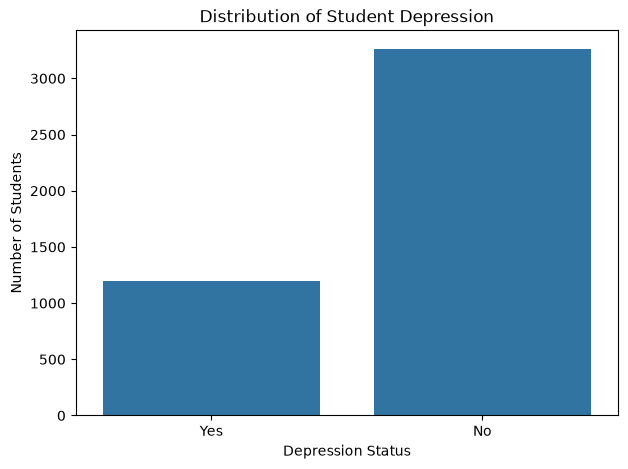

In [29]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Depression")

plt.title("Distribution of Student Depression")
plt.xlabel("Depression Status")
plt.ylabel("Number of Students")

plt.show()

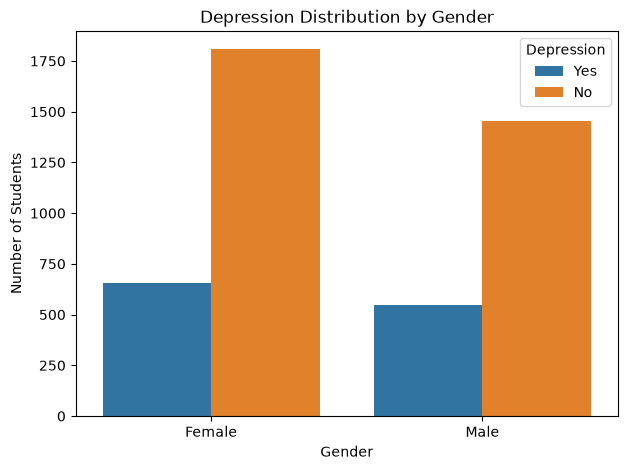

In [30]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Gender", hue="Depression")

plt.title("Depression Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Students")
plt.legend(title="Depression")

plt.show()

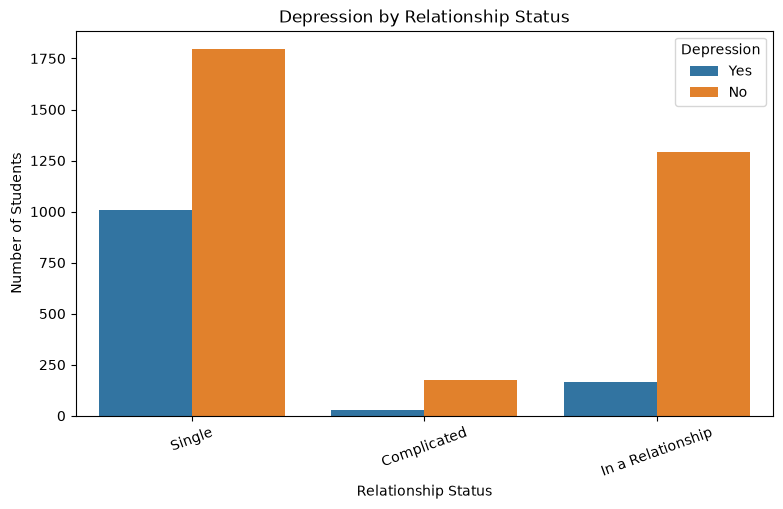

In [31]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="Relationship_status", hue="Depression")

plt.title("Depression by Relationship Status")
plt.xlabel("Relationship Status")
plt.ylabel("Number of Students")
plt.xticks(rotation=20)

plt.show()

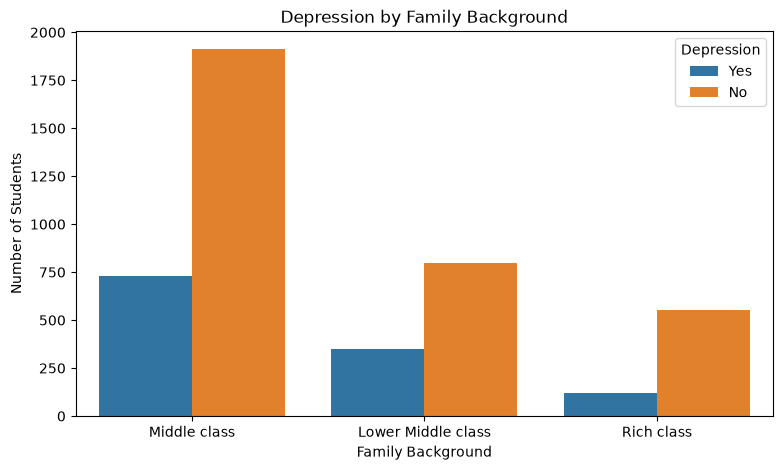

In [32]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="Family_background", hue="Depression")

plt.title("Depression by Family Background")
plt.xlabel("Family Background")
plt.ylabel("Number of Students")

plt.show()

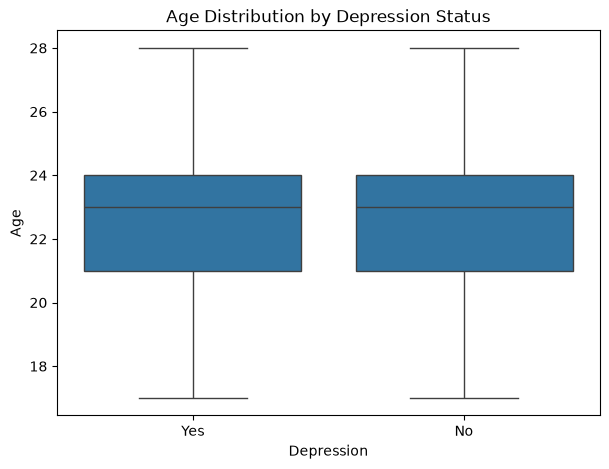

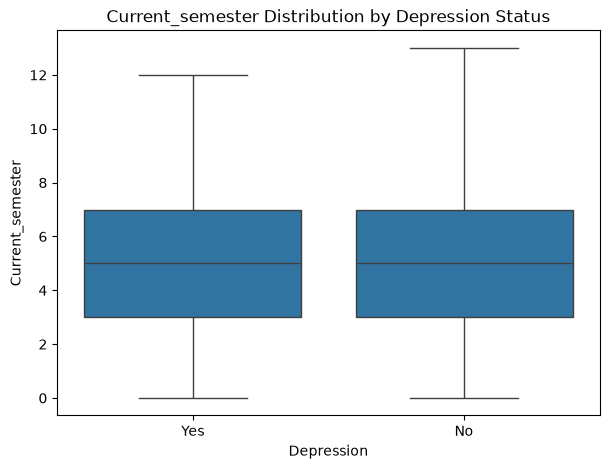

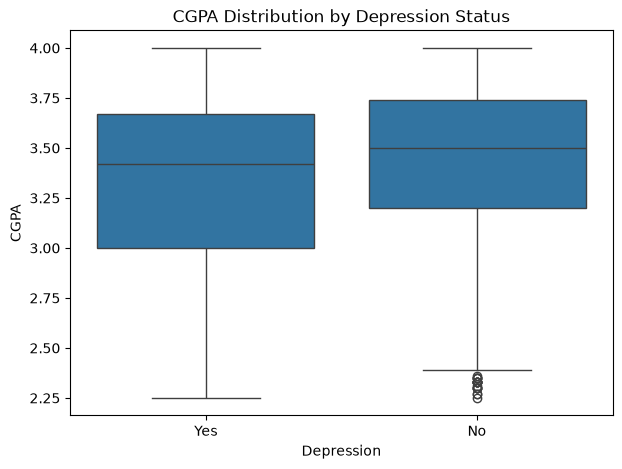

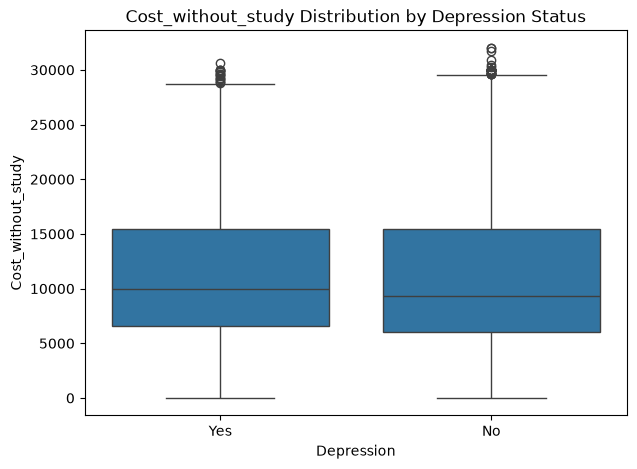

In [33]:
numerical_columns = [
    "Age",
    "Current_semester",
    "CGPA",
    "Cost_without_study"
]

for column in numerical_columns:
    plt.figure(figsize=(7, 5))

    sns.boxplot(data=df, x="Depression", y=column)

    plt.title(f"{column} Distribution by Depression Status")
    plt.show()

In [34]:
categorical_columns = [
    "Gender",
    "Family_background",
    "Relationship_status",
    "Marital_status",
    "Living_style",
    "friend_circle",
    "Health_condition",
    "Home_division"
]

for column in categorical_columns:
    print(f"\nDepression rate by {column}:")

    rates = pd.crosstab(
        df[column],
        df["Depression"],
        normalize="index"
    ) * 100

    display(rates.round(2))


Depression rate by Gender:


Depression,No,Yes
Gender,,
Female,73.40,26.60
Male,72.73,27.27



Depression rate by Family_background:


Depression,No,Yes
Family_background,,
Lower Middle class,69.42,30.58
Middle class,72.33,27.67
Rich class,82.41,17.59



Depression rate by Relationship_status:


Depression,No,Yes
Relationship_status,,
Complicated,86.76,13.24
In a Relationship,88.54,11.46
Single,64.07,35.93


... (6 outputs left out)


Depression rate by Health_condition:


Depression,No,Yes
Health_condition,,
Abnormal,45.06,54.94
Critical,0.00,100.00
Good,100.00,0.00
Normal,95.36,4.64



Depression rate by Home_division:


Depression,No,Yes
Home_division,,
Barisal,72.39,27.61
Chittagong,69.50,30.50
Dhaka,77.60,22.40
Khulna,68.98,31.02
Mymensingh,72.19,27.81
Rajshahi,68.44,31.56
Rangpur,68.04,31.96
Sylhet,76.40,23.60


In [38]:
features = df.drop("Depression", axis=1)

target = df["Depression"]
print("Features shape:", features.shape)
print("Target shape:", target.shape)

Features shape: (4464, 12)
Target shape: (4464,)


In [48]:
print(df["Depression"].unique())
print(df["Depression"].value_counts(dropna=False))
for value in df["Depression"].unique():
    print(repr(value))

<StringArray>
['Yes', 'No']
Length: 2, dtype: str
Depression
No     3263
Yes    1201
Name: count, dtype: int64
'Yes'
'No'


In [49]:
target = df["Depression"].map({
    "No": 0,
    "Yes": 1
})

print(target.value_counts())
print("Missing values:", target.isnull().sum())

Depression
0    3263
1    1201
Name: count, dtype: int64
Missing values: 0


In [50]:
from sklearn.model_selection import train_test_split

features_train, features_test, target_train, target_test = train_test_split(
    features,
    target,
    test_size=0.20,
    random_state=42,
    stratify=target
)

print("Training features:", features_train.shape)
print("Testing features:", features_test.shape)

print("Training target:", target_train.shape)
print("Testing target:", target_test.shape)

Training features: (3571, 12)
Testing features: (893, 12)
Training target: (3571,)
Testing target: (893,)
